In [2]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


**Chargement des données** 

In [3]:

cac = yf.download(
    "^FCHI",
    start="2014-12-15",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

cac.head()


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2014-12-15,4005.379883,4005.379883,4144.310059,4000.800049,4094.459961,149438700
2014-12-16,4093.199951,4093.199951,4094.189941,3926.340088,4027.510010,248244700
2014-12-17,4111.910156,4111.910156,4131.810059,4035.300049,4052.229980,143182000
2014-12-18,4249.490234,4249.490234,4249.490234,4159.950195,4186.259766,214450700
2014-12-19,4241.649902,4241.649902,4291.200195,4202.069824,4282.390137,214972700


In [4]:

sp500 = yf.download(
    "^GSPC",
    start="2014-12-15",
    end="2025-01-01",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

sp500.head()


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2014-12-15,1989.630005,1989.630005,2018.689941,1982.260010,2005.030029,4361990000
2014-12-16,1972.739990,1972.739990,2016.890015,1972.560059,1986.709961,4958680000
2014-12-17,2012.890015,2012.890015,2016.750000,1973.770020,1973.770020,4942370000
2014-12-18,2061.229980,2061.229980,2061.229980,2018.979980,2018.979980,4703380000
2014-12-19,2070.649902,2070.649902,2077.850098,2061.030029,2061.040039,6465530000


In [10]:
prix_cac = cac["Close"].dropna()
prix_sp500 = sp500["Close"].dropna()

**Calculer les rendements logarithmiques**

In [11]:
rendements_cac = np.log(prix_cac / prix_cac.shift(1))
rendements_sp500 = np.log(prix_sp500 / prix_sp500.shift(1))

rendements = pd.concat(
    [rendements_cac, rendements_sp500],
    axis=1
)

rendements.columns = ["CAC40", "SP500"]

rendements = rendements.loc["2015-01-01":"2024-12-31"]

rendements.head()

,CAC40,SP500
Date,,
2015-01-02,-0.004800,-0.000340
2015-01-05,-0.033704,-0.018447
2015-01-06,-0.006799,-0.008933
2015-01-07,0.007133,0.011563
2015-01-08,0.035227,0.017730


In [12]:
print(rendements.count())
print(rendements.isna().sum())

rendements.describe()

CAC40    2560
SP500    2516
dtype: int64
CAC40    23
SP500    67
dtype: int64


,CAC40,SP500
count,2560.000000,2516.000000
mean,0.000214,0.000417
std,0.011842,0.011267
min,-0.130983,-0.127652
25%,-0.005061,-0.003782
50%,0.000735,0.000635
75%,0.006153,0.005737
max,0.080561,0.089683


In [13]:
rendements_communs = rendements.dropna()

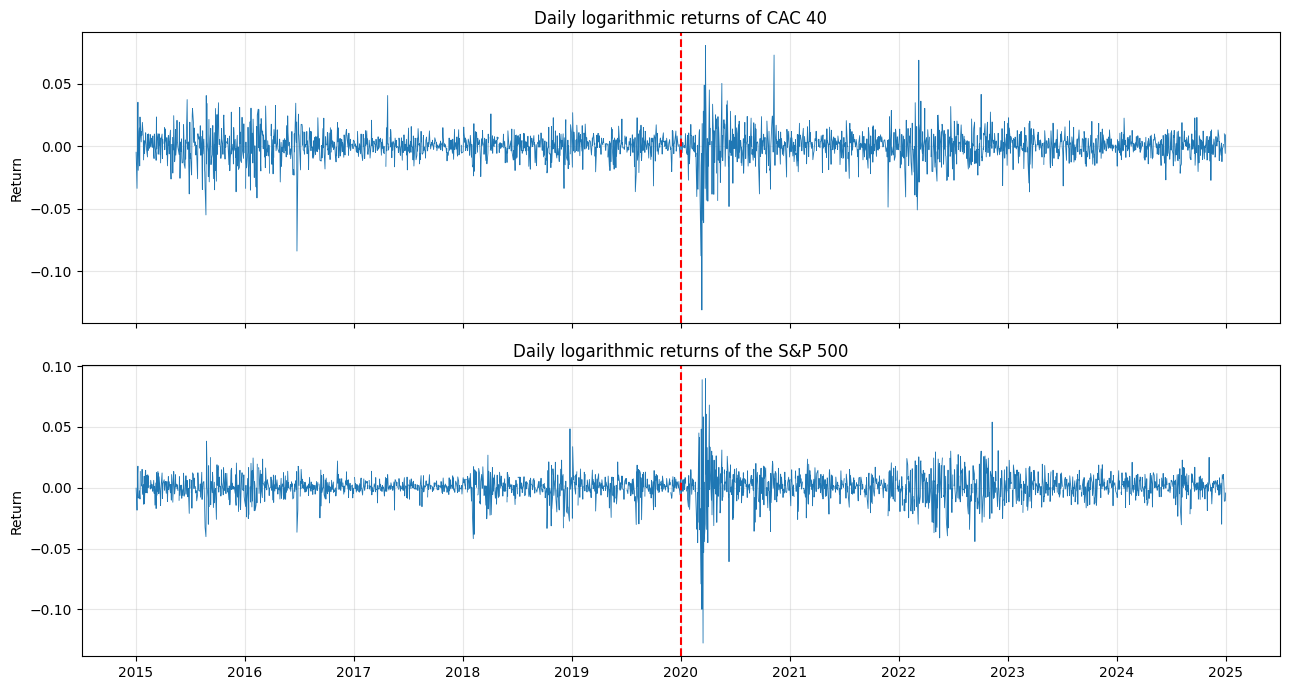

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

axes[0].plot(rendements.index, rendements["CAC40"], linewidth=0.6)
axes[0].set_title("Daily logarithmic returns of CAC 40")

axes[1].plot(rendements.index, rendements["SP500"], linewidth=0.6)
axes[1].set_title("Daily logarithmic returns of the S&P 500")

for ax in axes:
    ax.axvline(pd.Timestamp("2020-01-01"), color="red", linestyle="--")
    ax.set_ylabel("Return")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
cac_avant = rendements.loc["2015":"2019", "CAC40"].dropna()
cac_apres = rendements.loc["2020":"2024", "CAC40"].dropna()

sp500_avant = rendements.loc["2015":"2019", "SP500"].dropna()
sp500_apres = rendements.loc["2020":"2024", "SP500"].dropna()

In [16]:
statistiques = pd.concat(
    [
        cac_avant.describe(),
        cac_apres.describe(),
        sp500_avant.describe(),
        sp500_apres.describe()
    ],
    axis=1
)

statistiques.columns = [
    "CAC40 2015-2019",
    "CAC40 2020-2024",
    "SP500 2015-2019",
    "SP500 2020-2024"
]

statistiques

,CAC40 2015-2019,CAC40 2020-2024,SP500 2015-2019,SP500 2020-2024
count,1277.000000,1283.000000,1258.000000,1258.000000
mean,0.000263,0.000164,0.000358,0.000476
std,0.010610,0.012957,0.008477,0.013496
min,-0.083844,-0.130983,-0.041843,-0.127652
25%,-0.004859,-0.005526,-0.002942,-0.005319
50%,0.000564,0.000792,0.000491,0.000895
75%,0.005768,0.006519,0.004622,0.007256
max,0.040604,0.080561,0.048403,0.089683


**Autocorrélation et ACF**

In [17]:
carres_cac_avant = (cac_avant - cac_avant.mean()) ** 2
carres_cac_apres = (cac_apres - cac_apres.mean()) ** 2

carres_sp500_avant = (sp500_avant - sp500_avant.mean()) ** 2
carres_sp500_apres = (sp500_apres - sp500_apres.mean()) ** 2

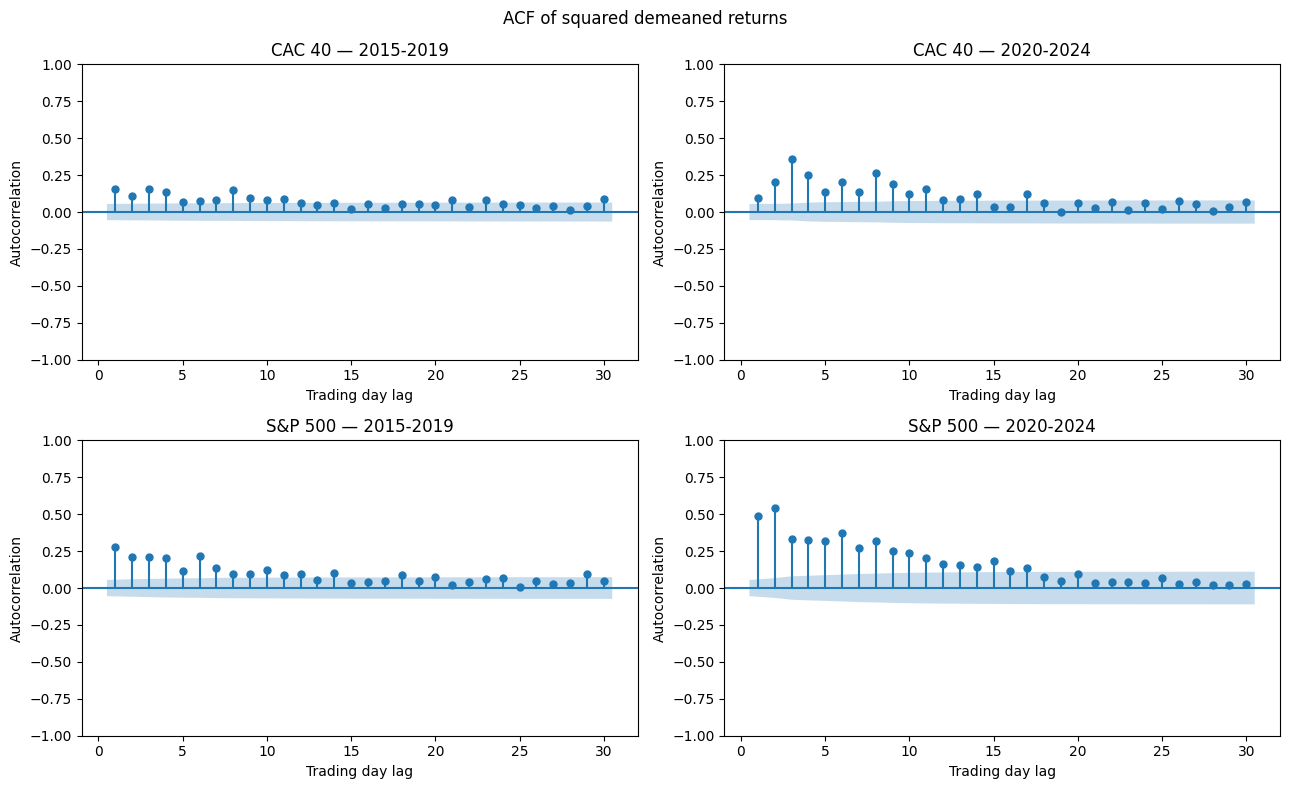

In [21]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

plot_acf(
    carres_cac_avant, ax=axes[0, 0], lags=30, zero=False,
    title="CAC 40 — 2015-2019"
)

plot_acf(
    carres_cac_apres, ax=axes[0, 1], lags=30, zero=False,
    title="CAC 40 — 2020-2024"
)

plot_acf(
    carres_sp500_avant, ax=axes[1, 0], lags=30, zero=False,
    title="S&P 500 — 2015-2019"
)

plot_acf(
    carres_sp500_apres, ax=axes[1, 1], lags=30, zero=False,
    title="S&P 500 — 2020-2024"
)

for ax in axes.flat:
    ax.set_xlabel("Trading day lag")
    ax.set_ylabel("Autocorrelation")

fig.suptitle("ACF of squared demeaned returns")
plt.tight_layout()
plt.show()

In [22]:
# Correction de la variance car autocorrélation

def variance_long_terme(serie, L=20):
    x = np.asarray(serie, dtype=float)
    n = len(x)

    if not 0 <= L < n:
        raise ValueError("L doit être compris entre 0 et n - 1.")

    x = x - x.mean()

    # Variance de la série
    v = np.dot(x, x) / n

    # Autocovariances avec les poids de Bartlett
    for h in range(1, L + 1):
        gamma = np.dot(x[h:], x[:-h]) / n
        poids = 1 - h / (L + 1)
        v = v + 2 * poids * gamma

    return v


from scipy.stats import norm

# La moyenne des carrés centrés estime la variance des rendements
variance_avant = carres_cac_avant.mean()
variance_apres = carres_cac_apres.mean()

# Correction pour la dépendance temporelle
v_avant = variance_long_terme(carres_cac_avant, L=20)
v_apres = variance_long_terme(carres_cac_apres, L=20)

n_avant = len(carres_cac_avant)
n_apres = len(carres_cac_apres)

difference_cac = variance_apres - variance_avant

erreur_cac = np.sqrt(
    v_avant / n_avant + v_apres / n_apres
)

z_cac = difference_cac / erreur_cac
p_cac = 2 * norm.sf(abs(z_cac))

print("CAC 40 — Test de différence de variances (avant et après 2020)")
print(f"Différence de variances après - avant : {difference_cac:.8f}")
print(f"Erreur standard corrigée : {erreur_cac:.8f}")
print(f"Statistique Z : {z_cac:.3f}")
print(f"P-value : {p_cac:.6g}")

CAC 40 — Test de différence de variances (avant et après 2020)
Différence de variances après - avant : 0.00005528
Erreur standard corrigée : 0.00004132
Statistique Z : 1.338
P-value : 0.181031


In [24]:
variance_sp500_avant = carres_sp500_avant.mean()
variance_sp500_apres = carres_sp500_apres.mean()

v_sp500_avant = variance_long_terme(carres_sp500_avant, L=20)
v_sp500_apres = variance_long_terme(carres_sp500_apres, L=20)

n_sp500_avant = len(carres_sp500_avant)
n_sp500_apres = len(carres_sp500_apres)

difference_sp500 = variance_sp500_apres - variance_sp500_avant

erreur_sp500 = np.sqrt(
    v_sp500_avant / n_sp500_avant
    + v_sp500_apres / n_sp500_apres
)

z_sp500 = difference_sp500 / erreur_sp500
p_sp500 = 2 * norm.sf(abs(z_sp500))

print("S&P 500 — Test de différence de variances (avant et après 2020)")
print(f"Différence de variances après - avant : {difference_sp500:.8f}")
print(f"Erreur standard corrigée : {erreur_sp500:.8f}")
print(f"Statistique Z : {z_sp500:.3f}")
print(f"P-value : {p_sp500:.6g}")

S&P 500 — Test de différence de variances (avant et après 2020)
Différence de variances après - avant : 0.00011020
Erreur standard corrigée : 0.00005589
Statistique Z : 1.972
P-value : 0.0486602


In [25]:
resultats_retards = []

for nom, avant, apres in [
    ("CAC40", carres_cac_avant, carres_cac_apres),
    ("SP500", carres_sp500_avant, carres_sp500_apres)
]:
    for L in [10, 20, 40]:
        difference = apres.mean() - avant.mean()

        erreur = np.sqrt(
            variance_long_terme(avant, L=L) / len(avant)
            + variance_long_terme(apres, L=L) / len(apres)
        )

        z = difference / erreur
        p = 2 * norm.sf(abs(z))

        resultats_retards.append([nom, L, z, p])

sensibilite = pd.DataFrame(
    resultats_retards,
    columns=["Indice", "Retards", "Z", "P-value"]
)

sensibilite

,Indice,Retards,Z,P-value
0,CAC40,10,1.607561,0.107931
1,CAC40,20,1.337586,0.181031
2,CAC40,40,1.160421,0.245877
3,SP500,10,2.381621,0.017237
4,SP500,20,1.971557,0.048660
5,SP500,40,1.742433,0.081433
